# Momentum + trend filter, intraday rebalance (hourly bars)

The intraday analog of `momentum_trend_filter_ibkr_backtest.ipynb`: same two-stage filter —
rank by trailing momentum, narrow to names still in a confirmed long-term uptrend, buy the
survivors — but re-evaluated every few hourly bars instead of once a month. Tickers come from
`equities-list.csv` (rows with `Asset Type == Stock`; ETFs excluded, same as the original).
The CSV labels these as halal *candidates* only — independently verify current Shariah
compliance before investing.

**This notebook picks its own rebalance cadence empirically**, rather than assuming the
rotation strategy's 2-hour cadence carries over unchanged — this strategy has a skip period
and a slow structural trend filter the rotation strategy doesn't, so there's no reason to
assume the same window is right here. See "Choosing a rebalance window" below.

**Strategy specification (unchanged from the original)**

1. Rank the universe by trailing momentum, skipping the most recent period (the "12-1" style
   skip, to avoid short-term reversal effects).
2. Narrow to the top 30% of that ranking.
3. Within that shortlist, keep only names trading above their own 200-*trading-day* SMA
   (1,400 hourly bars at 7 bars/session) — deliberately **not** rescaled to the rebalance
   cadence below, since this filter's whole point is to be a slow, structural confirmation,
   not something that should get faster just because the rebalance clock does.
4. Buy the top 15 names (by momentum rank) that pass both filters, equal-weighted. Unfilled
   slots sit in cash rather than being redistributed to the names that did qualify — the
   original notebook divides realized return by the *fixed* target of 15, not by however many
   slots actually filled, and this notebook does the same.
5. If fewer than `MIN_UNIVERSE` names are even scoreable, the whole portfolio goes to cash for
   that cycle (0% return) — this is also unchanged from the original, and is a different
   fallback than the rotation strategy uses (which holds its previous basket instead).


In [1]:
from pathlib import Path
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'hourly'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

START_DATE = pd.Timestamp('2009-01-01', tz='UTC')

# Strategy parameters unchanged from the monthly/hourly-monthly notebooks.
MOMENTUM_TOP_PCT = 0.30
TOP_N = 15
MIN_UNIVERSE = 20

# Trend filter stays anchored to its original trading-day horizon regardless of rebalance
# cadence (see markdown above) — 200 sessions x 7 bars/session.
BARS_PER_SESSION = 7
TRADING_DAYS_PER_YEAR = 252
SMA_WINDOW_DAYS = 200
SMA_WINDOW_BARS = SMA_WINDOW_DAYS * BARS_PER_SESSION

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED


132 candidate halal stocks in the universe


## Load the cached hourly bars and build the trend filter

Reuses the same `data/hourly/{TICKER}.csv` cache as every other hourly notebook in this
project. The 200-session SMA is computed once here, independent of whatever rebalance cadence
ends up chosen below.

In [2]:
def load_cached_hourly(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

hourly_closes = {}
missing = []
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        missing.append(ticker)
        continue
    bars = load_cached_hourly(ticker)
    if bars.empty:
        missing.append(ticker)
        continue
    hourly_closes[ticker] = bars['close']

if missing:
    print(f'{len(missing)} tickers missing from the hourly cache, excluded: {missing}')

price_panel = pd.DataFrame(hourly_closes).sort_index()
price_panel = price_panel.loc[price_panel.index >= START_DATE]
price_panel = price_panel.ffill(limit=BARS_PER_SESSION)

sma_trend = price_panel.rolling(SMA_WINDOW_BARS, min_periods=SMA_WINDOW_BARS).mean()

print(f'{price_panel.shape[1]} tickers, {price_panel.shape[0]:,} hourly bars '
      f'from {price_panel.index.min()} to {price_panel.index.max()}')


132 tickers, 32,366 hourly bars from 2009-01-02 14:30:00+00:00 to 2026-09-30 16:00:00+00:00


## Backtest engine

A single parameterized function — `lookback_bars` and `skip_bars` are the momentum window and
skip, `rebalance_bars` is how often the whole thing re-evaluates. Return-averaging, like every
other notebook in this project: for a strategy that fully rebalances every cycle, the
equal-weighted average of the selected names\' returns is mathematically identical to actually
liquidating and rebuying. Unfilled slots are divided into the fixed `TOP_N`, not redistributed
(`realized.sum() / TOP_N`, not `.mean()`) — matching the original exactly.

In [3]:
def run_backtest(rebalance_bars, lookback_bars, skip_bars):
    dates = price_panel.index
    n = len(dates)
    min_i = lookback_bars + skip_bars + rebalance_bars

    portfolio_returns = pd.Series(index=dates, dtype=float)
    holdings_log = {}

    for j in range(min_i, n - rebalance_bars, rebalance_bars):
        hold_start, hold_end = dates[j], dates[j + rebalance_bars]
        end_idx = j - skip_bars
        start_idx = end_idx - lookback_bars
        momentum_score = (price_panel.iloc[end_idx] / price_panel.iloc[start_idx] - 1).dropna()

        if len(momentum_score) < MIN_UNIVERSE:
            holdings_log[hold_end] = []
            portfolio_returns.loc[hold_end] = 0.0
            continue

        ranked = momentum_score.sort_values(ascending=False)
        momentum_cutoff = max(1, int(np.ceil(len(ranked) * MOMENTUM_TOP_PCT)))
        momentum_candidates = ranked.index[:momentum_cutoff]

        price_now = price_panel.iloc[j]
        sma_now = sma_trend.iloc[j]
        trend_ok = (price_now > sma_now) & price_now.notna() & sma_now.notna()

        passing = ranked.loc[[t for t in momentum_candidates if trend_ok.get(t, False)]]
        selected = passing.sort_values(ascending=False).head(TOP_N).index.tolist()

        holdings_log[hold_end] = selected
        if selected:
            realized = (price_panel.loc[hold_end, selected] / price_panel.loc[hold_start, selected] - 1).fillna(0.0)
            portfolio_returns.loc[hold_end] = realized.sum() / TOP_N
        else:
            portfolio_returns.loc[hold_end] = 0.0

    portfolio_returns = portfolio_returns.dropna()
    invested_fraction = pd.Series({d: len(h) / TOP_N for d, h in holdings_log.items()}).reindex(portfolio_returns.index)
    return portfolio_returns, holdings_log, invested_fraction


## Choosing a rebalance window

Rather than assuming the rotation strategy\'s 2-hour cadence applies here too, this tests a
small grid of rebalance cadences, each keeping the original 12-month-lookback / 1-month-skip
spec\'s **12:1:1 ratio** (lookback:skip:rebalance), just translated to bars. A 2-hour rebalance
with a 12:1 lookback ratio means a 24-bar (~3.4 trading day) lookback and a 2-bar skip — the
same proportions as "12 months of momentum, skip the most recent month, rebalance monthly,"
scaled down. Annualized Sharpe is the primary selection criterion, since it\'s the metric most
comparable across cadences with very different observation counts.

In [4]:
def annualized_stats(portfolio_returns, rebalance_bars):
    periods_per_year = (BARS_PER_SESSION * TRADING_DAYS_PER_YEAR) / rebalance_bars
    wealth = (1 + portfolio_returns).cumprod()
    years = (portfolio_returns.index[-1] - portfolio_returns.index[0]).days / 365.2425
    cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0) if years > 0 else float('nan')
    vol = float(portfolio_returns.std() * np.sqrt(periods_per_year))
    sharpe = float((portfolio_returns.mean() * periods_per_year) / vol) if vol else float('nan')
    drawdown = float((wealth / wealth.cummax() - 1.0).min())
    return {'rebalance_bars': rebalance_bars, 'cycles': len(portfolio_returns), 'CAGR': cagr,
            'annualized_vol': vol, 'sharpe': sharpe, 'max_drawdown': drawdown,
            'final_multiple': float(wealth.iloc[-1])}

grid_results = []
grid_cache = {}
for rebalance_bars in (1, 2, 4, 8):
    lookback_bars = 12 * rebalance_bars
    skip_bars = 1 * rebalance_bars
    portfolio_returns, holdings_log, invested_fraction = run_backtest(rebalance_bars, lookback_bars, skip_bars)
    grid_cache[rebalance_bars] = (portfolio_returns, holdings_log, invested_fraction)
    row = annualized_stats(portfolio_returns, rebalance_bars)
    row['lookback_bars'] = lookback_bars
    row['skip_bars'] = skip_bars
    row['avg_slots_filled'] = float((invested_fraction * TOP_N).mean())
    grid_results.append(row)

grid_table = pd.DataFrame(grid_results).set_index('rebalance_bars')
display(grid_table.round(3))

REBALANCE_BARS = int(grid_table['sharpe'].idxmax())
LOOKBACK_BARS = int(grid_table.loc[REBALANCE_BARS, 'lookback_bars'])
SKIP_BARS = int(grid_table.loc[REBALANCE_BARS, 'skip_bars'])
print(f'\nChosen: REBALANCE_BARS={REBALANCE_BARS} (~{REBALANCE_BARS}-hour rebalance), '
      f'LOOKBACK_BARS={LOOKBACK_BARS}, SKIP_BARS={SKIP_BARS} — highest Sharpe in the grid.')


,cycles,CAGR,annualized_vol,sharpe,max_drawdown,final_multiple,lookback_bars,skip_bars,avg_slots_filled
rebalance_bars,,,,,,,,,
1,32351,0.106,0.181,0.626,-0.277,5.923,12,1,13.512
2,16168,0.112,0.180,0.659,-0.292,6.553,24,2,13.600
4,8077,0.154,0.184,0.845,-0.327,12.678,48,4,13.722
8,4031,0.180,0.189,0.939,-0.300,18.499,96,8,13.882



Chosen: REBALANCE_BARS=8 (~8-hour rebalance), LOOKBACK_BARS=96, SKIP_BARS=8 — highest Sharpe in the grid.


The rest of this notebook uses whichever cadence the grid above selected (see the printed
`REBALANCE_BARS` / `LOOKBACK_BARS` / `SKIP_BARS` just above) — re-run from here down if you
want to see the full detail for a different choice from the grid.

In [5]:
portfolio_returns, holdings_log, invested_fraction = grid_cache[REBALANCE_BARS]
wealth = (1 + portfolio_returns).cumprod()
print(f'{len(portfolio_returns):,} tradable cycles, average {invested_fraction.mean():.0%} of '
      f'the target {TOP_N} slots filled, {(invested_fraction == 0).mean():.0%} of cycles fully in cash')


4,031 tradable cycles, average 93% of the target 15 slots filled, 4% of cycles fully in cash


### Latest cycle: example ranking and filters

In [6]:
last_hold_date = max(holdings_log)
dates = price_panel.index
j = list(dates).index(last_hold_date) - REBALANCE_BARS
end_idx = j - SKIP_BARS
start_idx = end_idx - LOOKBACK_BARS
last_score = (price_panel.iloc[end_idx] / price_panel.iloc[start_idx] - 1).dropna()
last_ranked = last_score.sort_values(ascending=False)
last_cutoff = max(1, int(np.ceil(len(last_ranked) * MOMENTUM_TOP_PCT)))

last_price = price_panel.iloc[j]
last_sma = sma_trend.iloc[j]

example_table = last_ranked.to_frame('trailing_lookback_return')
example_table['rank'] = range(1, len(example_table) + 1)
example_table['in_momentum_top30'] = example_table.index.isin(last_ranked.index[:last_cutoff])
example_table['price'] = last_price.reindex(example_table.index)
example_table['sma_trend'] = last_sma.reindex(example_table.index)
example_table['above_sma_trend'] = example_table['price'] > example_table['sma_trend']
example_table['selected'] = example_table.index.isin(holdings_log[last_hold_date])
example_table['trailing_lookback_return'] = (example_table['trailing_lookback_return'] * 100).round(1)
example_table[['price', 'sma_trend']] = example_table[['price', 'sma_trend']].round(2)
print(f'Ranking and filters used to form the basket held through {last_hold_date}:')
display(example_table[example_table['in_momentum_top30']].head(30))


Ranking and filters used to form the basket held through 2026-09-30 12:00:00+00:00:


,trailing_lookback_return,rank,in_momentum_top30,price,sma_trend,above_sma_trend,selected
DHR,11.9,1,True,NaN,NaN,False,False
ISRG,10.8,2,True,NaN,NaN,False,False
TMO,10.2,3,True,NaN,NaN,False,False
ASX,9.7,4,True,43.78,33.35,True,True
NVS,6.6,5,True,146.92,152.53,False,False
UMC,5.8,6,True,23.85,17.20,True,True
URI,4.9,7,True,1044.15,966.59,True,True
AZN,4.7,8,True,166.31,181.66,False,False
EMR,4.4,9,True,159.41,144.29,True,True
HON,4.1,10,True,211.52,232.62,False,False


## General statistics

In [7]:
def max_drawdown(w):
    return float((w / w.cummax() - 1.0).min())

periods_per_year = (BARS_PER_SESSION * TRADING_DAYS_PER_YEAR) / REBALANCE_BARS
start_date, end_date = portfolio_returns.index[0], portfolio_returns.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(wealth.iloc[-1] - 1.0)
cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(portfolio_returns.std() * np.sqrt(periods_per_year))
sharpe_rf0 = float((portfolio_returns.mean() * periods_per_year) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'observations_cycles': len(portfolio_returns),
    'start': start_date,
    'end': end_date,
    'avg_slots_filled_of_target': float((invested_fraction * TOP_N).mean()),
    'pct_cycles_fully_in_cash': float((invested_fraction == 0).mean()),
    'mean_cycle_return': float(portfolio_returns.mean()),
    'median_cycle_return': float(portfolio_returns.median()),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(wealth),
    'final_wealth_multiple': float(wealth.iloc[-1]),
})
display(stats.to_frame('value'))


,value
observations_cycles,4031
start,2009-01-28 15:00:00+00:00
end,2026-09-30 12:00:00+00:00
avg_slots_filled_of_target,13.882163
pct_cycles_fully_in_cash,0.03994
mean_cycle_return,0.000805
median_cycle_return,0.000984
total_return,17.49892
CAGR,0.179563
annualized_volatility,0.189164


## $150 simulation

In [8]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * wealth.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))


CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,1760.027499
nominal_gain,1664.885325
total_return,17.498920
CAGR,0.179563
ending_value_in_target_dollars,1760.027499
real_gain_vs_target_dollars,1610.027499


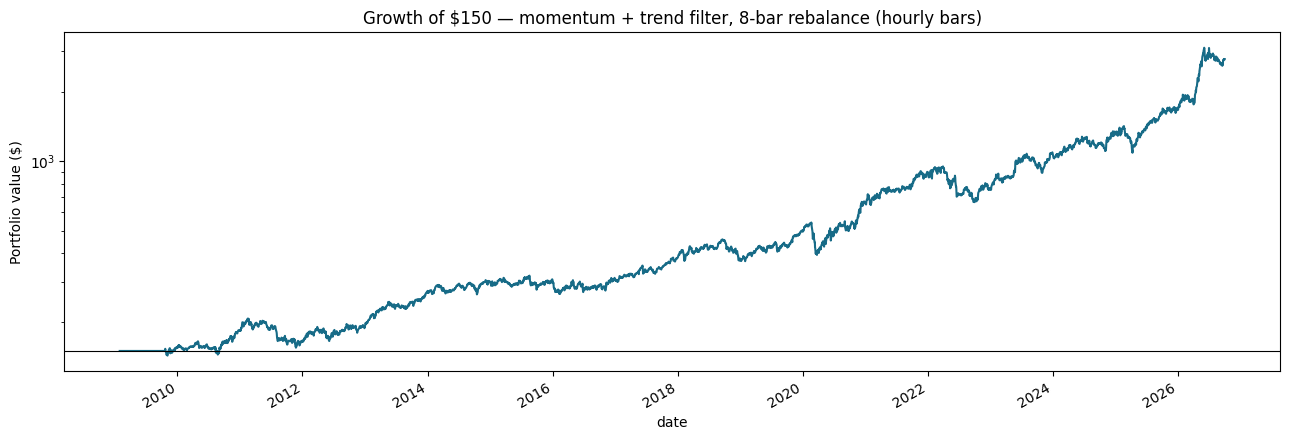

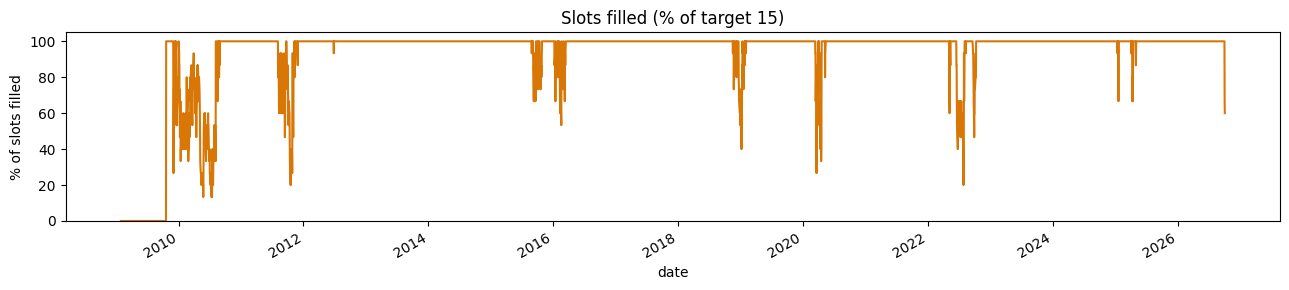

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
(150 * wealth / wealth.iloc[0]).plot(ax=ax, color='#176b87',
    title=f'Growth of $150 \u2014 momentum + trend filter, {REBALANCE_BARS}-bar rebalance (hourly bars)')
ax.set_ylabel('Portfolio value ($)')
ax.set_yscale('log')
ax.axhline(150, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3))
(invested_fraction * 100).plot(ax=ax, color='#d97706', title=f'Slots filled (% of target {TOP_N})')
ax.set_ylabel('% of slots filled')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


## Monthly performance

Resampled to month-end so this reads on the same heatmap as every other notebook, even though
it actually trades every few hours.

In [10]:
monthly_wealth = wealth.resample('ME').last()
today_ts = pd.Timestamp.now(tz='UTC')
if len(monthly_wealth) and (monthly_wealth.index[-1].year, monthly_wealth.index[-1].month) == (today_ts.year, today_ts.month):
    monthly_wealth = monthly_wealth.iloc[:-1]
monthly_returns = monthly_wealth.pct_change().dropna()

table = (monthly_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = monthly_returns.groupby(monthly_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(monthly_returns),
    'positive_months': int((monthly_returns > 0).sum()),
    'pct_positive_months': float((monthly_returns > 0).mean()),
    'avg_monthly_return': float(monthly_returns.mean()),
    'median_monthly_return': float(monthly_returns.median()),
    'best_month': monthly_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(monthly_returns.max()),
    'worst_month': monthly_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(monthly_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-15, vmax=15, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-3.4,1.7,4.9,3.0
2010,-0.2,-1.2,2.8,5.4,-5.4,-0.4,-0.8,-4.6,11.0,2.8,2.6,6.6,19.0
2011,6.7,1.0,-0.4,2.6,-1.6,-4.5,-2.3,-7.8,-4.7,1.9,-2.1,1.7,-10.0
2012,4.7,4.3,3.0,-1.3,-6.3,5.8,-1.8,2.8,2.0,0.6,1.5,0.7,16.5
2013,8.5,1.4,7.7,0.0,4.3,-1.6,-1.0,-1.0,5.6,2.8,1.7,7.6,41.7
2014,-1.6,7.5,-3.3,-2.9,1.6,5.0,-2.7,4.7,-2.6,0.7,2.8,0.6,9.5
2015,-3.0,6.0,-1.9,-4.6,1.9,0.2,6.1,-4.7,-5.7,4.6,2.7,0.8,1.4
2016,-9.3,1.0,2.6,4.2,-1.0,-5.4,1.1,0.6,1.6,-0.9,6.2,0.6,0.3
2017,2.4,2.2,1.3,-0.4,6.9,-3.7,2.6,-1.1,2.0,5.4,4.5,0.6,24.6


,value
months,212
positive_months,131
pct_positive_months,0.617925
avg_monthly_return,0.0154
median_monthly_return,0.014308
best_month,2026-04
best_month_return,0.293085
worst_month,2022-06
worst_month_return,-0.142756


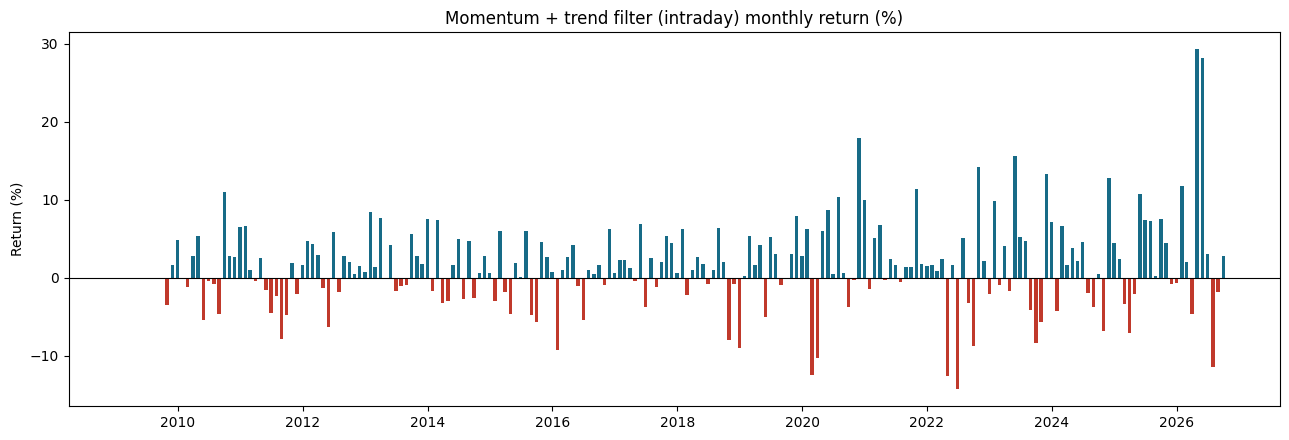

In [11]:
colors = np.where(monthly_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(monthly_returns.index, monthly_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Momentum + trend filter (intraday) monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()


## Caveats and next improvements

- **This strategy and cadence have never run live or been validated before this notebook.**
  Unlike the rotation strategy, there isn\'t even a live script for this one yet — this is
  pure backtest exploration.
- **The rebalance window was chosen by maximizing in-sample Sharpe over the full ~17-year
  history** — that\'s standard backtest practice, but it\'s still fitting a choice to the data
  it\'s then evaluated on, which flatters the result. A more rigorous version would pick the
  window on an earlier slice of history and validate out-of-sample on the rest.
- **No transaction costs**, and this strategy can trade far more often than its monthly
  ancestor — the same caveat as the rotation-intraday notebook, for the same reason.
- **The 200-day trend filter was deliberately not rescaled** to the rebalance cadence (see the
  intro) — if that turns out to matter a lot for performance, it\'s evidence the filter\'s
  effectiveness depends on operating on a genuinely different timescale than the entry/exit
  logic around it, which is worth understanding before trusting this with real capital.
- **Cash-drag is real here**: unlike the rotation strategy, this one can be partially or fully
  in cash whenever too few names pass both filters, which the "slots filled" chart above makes
  visible. A 2-hour-or-faster cadence re-checks that filter far more often than monthly does,
  so cash periods may be shorter but more frequent — not obviously better or worse, just
  different, and worth looking at the slots-filled chart rather than assuming.
- **Look-ahead / survivorship bias in the universe**: same caveat as every other notebook in
  this project.
